# Determinantes Socioeconômicos do Desempenho no ENADE 2018 (Ciências Econômicas): Estimação via MQO, Erros Robustos de White e FGLS

**Autor:** Matheus Brasil  
**Origem Acadêmica:** Universidade Federal do Paraná (UFPR) — Estatística Econômica e Introdução à Econometria (Refatoração de Portfólio)  
**Fonte de Dados:** Microdados Oficiais do ENADE 2018 (INEP / MEC)

---

## 1. Resumo Executivo e Contexto do Problema

O **Exame Nacional de Desempenho dos Estudantes (ENADE)**, instituído pela Lei nº 10.861/2004 no âmbito do SINAES, é uma avaliação censitária obrigatória aplicada aos concluintes do ensino superior brasileiro para mensurar o domínio de conteúdos programáticos e competências profissionais. Em 2018, o ciclo avaliativo contemplou **548.127 graduandos** distribuídos em **27 áreas** do conhecimento, incluindo **9.582 estudantes de Ciências Econômicas**.

Este projeto investiga em que medida o desempenho acadêmico na prova do ENADE (`NT_GER`, escala de 0 a 100) dos concluintes de **Ciências Econômicas** é explicado por fatores de **origem socioeconômica e capital cultural familiar** versus **esforço individual e restrição de tempo**, com foco econométrico rigoroso no **diagnóstico e tratamento da heterocedasticidade** em dados de corte transversal (*cross-section*).

### Hipóteses de Pesquisa
* **$H_1$ (Capital Cultural Familiar):** Estudantes cujos pais possuem ensino superior completo ou pós-graduação (`QE_I04`, `QE_I05`) apresentam desempenho médio superior devido ao maior suporte educacional, informacional e cultural.
* **$H_2$ (Formação Básica Prévia):** Egressos do ensino médio privado (`QE_I17`) obtêm notas maiores que egressos da rede pública, refletindo desigualdades estruturais de qualidade e preparação pré-universitária no Brasil.
* **$H_3$ (Esforço Extraclasse vs. Custo de Oportunidade do Trabalho):** Maior dedicação semanal aos estudos fora de sala de aula (`QE_I23`) eleva o desempenho, ao passo que jornadas intensas de trabalho remunerado (`QE_I10`) reduzem a disponibilidade de tempo e afetam negativamente a nota.

### Evolução Metodológica (Refatoração para Portfólio)
Em relação aos notebooks exploratórios originais desenvolvidos durante a graduação (2022), esta versão consolidada aplica correções e aprimoramentos técnicos substanciais:
1. **Unificação e Reprodutibilidade:** Consolidação de todo o fluxo em um único notebook executivo alimentado por pipeline ETL reproduzível (`src/etl_enade.py`) em `data/processed/`.
2. **Integridade da Amostra (`dropna` antes de `get_dummies`):** Correção do vazamento de valores ausentes ocorrido no código original, garantindo exatamente **$N = 8.024$** observações completas (em vez de $8.073$ com 49 registros nulos tratados como zeros nas variáveis *dummy*).
3. **Auditoria de `QE_I17` (Ensino Médio):** Tratamento explícito das categorias no exterior/parcial exterior (`C` e `F`), mantendo $N = 8.024$ como amostra base e validando a exclusão estrita ($N = 7.945$) na análise de sensibilidade.
4. **FGLS/WLS Legítimo + White HC3:** Substituição da ponderação arbitrária antiga (`weights = 1..N`) por **Mínimos Quadrados Generalizados Factíveis (FGLS/WLS)** com variância condicional estimada via regressão auxiliar log-linear ($\ln \hat{u}_i^2 = X_i \gamma + v_i$), somado à inferência moderna via **Erros-Padrão Robustos à Heterocedasticidade (`HC3`)**.
5. **Diagnósticos Completos e Robustez:** Correção da ordenação do teste de Goldfeld-Quandt, avaliação de heterocedasticidade pós-FGLS sobre resíduos padronizados (`wresid`), cálculo formal de **VIF** (*Variance Inflation Factor*) e estimação de especificações alternativas com **controle institucional (IES Pública vs. Privada)** e **faixas de renda familiar (`QE_I08`)**.


## 2. Metodologia Econométrica

### 2.1 Modelo Base de Regressão Linear Múltipla (MQO / OLS)

A especificação base relaciona a Nota Geral no ENADE (`NT_GER`) às variáveis de origem familiar, formação básica e alocação de tempo:

$$\text{NT\_GER}_i = \beta_0 + \beta_1 \text{PaiSup}_i + \beta_2 \text{MaeSup}_i + \beta_3 \text{EMPrivado}_i + \sum_{j=1}^{4} \delta_j \text{Estudo}_{ji} + \sum_{m=1}^{4} \theta_m \text{Trabalho}_{mi} + u_i$$

Onde as categorias de referência (omitidas para evitar armadilha das *dummies*) são:
* Pais sem ensino superior completo ($\text{PaiSup}=0$, $\text{MaeSup}=0$);
* Ensino médio integralmente ou majoritariamente em escola pública ($\text{EMPrivado}=0$);
* Nenhuma hora de estudo extraclasse semanal (`QE_I23 = A`);
* Não trabalha (`QE_I10 = A`).

Segundo o **Teorema de Gauss-Markov** (Lewis-Beck, 1980; Kennedy, 2009; Gujarati & Porter, 2011), sob os pressupostos clássicos — linearidade nos parâmetros, exogeneidade estrita ($E[u_i \mid X] = 0$), ausência de colinearidade perfeita, independência entre observações e **homocedasticidade** ($\text{Var}(u_i \mid X) = \sigma^2$) —, o estimador de Mínimos Quadrados Ordinários ($\hat{\beta}_{\text{OLS}} = (X^T X)^{-1} X^T y$) é o **Melhor Estimador Linear Não-Viesado (MELNV / BLUE)**.

---

### 2.2 O Problema da Heterocedasticidade em Dados de Corte Transversal

Em microdados educacionais de corte transversal (*cross-section*), estudantes de diferentes estratos socioeconômicos e rotinas acadêmicas apresentam dispersões heterogêneas de desempenho:

$$\text{Var}(u_i \mid X_i) = \sigma_i^2 \neq \sigma^2$$

Na presença de heterocedasticidade:
* $\hat{\beta}_{\text{OLS}}$ permanece **não-viesado e consistente** (desde que $E[u_i \mid X_i] = 0$);
* Contudo, $\hat{\beta}_{\text{OLS}}$ **deixa de ter variância mínima** (perde eficiência);
* A matriz de variância-covariância clássica $\hat{\sigma}^2 (X^T X)^{-1}$ torna-se **viesada e inconsistente**, invalidando erros-padrão, intervalos de confiança e estatísticas $t$ e $F$.

---

### 2.3 Testes Formais de Diagnóstico

1. **Teste de Goldfeld-Quandt:** Ordena as observações segundo uma variável explicativa suspeita (ou pelo valor ajustado $\hat{y}_i$), omite $c$ observações centrais e compara a soma dos quadrados dos resíduos dos extremos:
   $$\lambda = \frac{\text{SQR}_2 / gl}{\text{SQR}_1 / gl} \sim F_{(gl,\, gl)}$$
   *(Nota metodológica: se aplicado sem especificar a variável de ordenação em regressores com intercepto na coluna 0, o teste ordena arbitrariamente pela constante e perde poder estatístico).*

2. **Teste de Breusch-Pagan-Godfrey:** Regride os resíduos quadrados normalizados sobre os regressores originais $X$:
   $$\text{LM} = n \cdot R^2_{\hat{u}^2 \sim X} \xrightarrow{d} \chi^2_k \quad (\text{sob } H_0\text{: homocedasticidade})$$

3. **Teste de White:** Generaliza o teste anterior incluindo termos quadráticos e produtos cruzados dos regressores, sem depender da hipótese de normalidade dos erros:
   $$\hat{u}_i^2 = \alpha_0 + \sum_{j=1}^k \alpha_j X_{ji} + \sum_{j=1}^k \sum_{s \ge j}^k \gamma_{js} X_{ji} X_{si} + v_i, \qquad \text{LM} = n \cdot R^2_{\text{aux}} \xrightarrow{d} \chi^2_p$$

4. **Multicolinearidade (VIF), Autocorrelação (Durbin-Watson) e Normalidade (Jarque-Bera):**
   $$\text{VIF}_j = \frac{1}{1 - R_j^2}, \qquad d = \frac{\sum_{i=2}^n (\hat{u}_i - \hat{u}_{i-1})^2}{\sum_{i=1}^n \hat{u}_i^2}, \qquad \text{JB} = \frac{n}{6}\left(S^2 + \frac{(K - 3)^2}{4}\right)$$

---

### 2.4 Estratégias de Correção Adotadas

* **OLS com Erros-Padrão Robustos de White (`HC3`):** Mantém $\hat{\beta}_{\text{OLS}}$ e corrige a matriz de covariância usando a estimativa robusta de MacKinnon-White (`HC3`), altamente recomendada para amostras transversais:
  $$\widehat{\text{Var}}_{\text{HC3}}(\hat{\beta}) = (X^T X)^{-1} \left( \sum_{i=1}^n \frac{\hat{u}_i^2}{(1 - h_{ii})^2} \, x_i x_i^T \right) (X^T X)^{-1}$$

* **Mínimos Quadrados Generalizados Factíveis (`FGLS` / `WLS`):** Modela explicitamente a variância condicional exponencial garantindo pesos estritamente positivos ($\hat{\sigma}_i^2 > 0$):
  $$\ln(\hat{u}_i^2) = X_i \gamma + v_i \implies \hat{h}_i = \exp(X_i \hat{\gamma}), \qquad w_i = \frac{1}{\hat{h}_i}$$
  $$\hat{\beta}_{\text{FGLS}} = (X^T W X)^{-1} X^T W y, \qquad W = \text{diag}(w_1, \dots, w_n)$$


## 3. Importação, Auditoria da Amostra e Tratamento de Dados


In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.diagnostic import (
    het_breuschpagan,
    het_goldfeldquandt,
    het_white,
)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.tools.sm_exceptions import ValueWarning

# Caminhos do projeto
PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "data" / "processed"
ASSETS_DIR = PROJECT_ROOT / "assets"
ASSETS_DIR.mkdir(parents=True, exist_ok=True)

# Configuração visual executiva global
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelsize": 10.5,
    "font.size": 10,
    "grid.alpha": 0.25,
})

PALETTE = {
    "navy": "#1E3A8A",
    "teal": "#0F766E",
    "coral": "#DC2626",
    "amber": "#D97706",
    "slate": "#475569",
    "light_blue": "#3B82F6",
}

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")


### 3.1 Panorama Nacional do ENADE 2018 (27 Áreas Avaliadas)

Antes de mergulhar no recorte de Ciências Econômicas, auditamos os números consolidados do ENADE 2018 a partir da tabela processada `enade_2018_resumo_cursos.csv`, verificando o total nacional de inscritos, a taxa de participação efetiva com nota válida e a distribuição entre IES Públicas e Privadas.


In [2]:
resumo_cursos = pd.read_csv(DATA_DIR / "enade_2018_resumo_cursos.csv")
econ_raw = pd.read_csv(DATA_DIR / "enade_2018_economia.csv")

total_inscritos_br = int(resumo_cursos["total_inscritos"].sum())
total_presentes_br = int(resumo_cursos["total_presentes"].sum())
taxa_presenca_br = total_presentes_br / total_inscritos_br * 100

print(f"Total nacional de estudantes na base ENADE 2018 : {total_inscritos_br:,}".replace(",", "."))
print(f"Total nacional com Nota Geral (NT_GER) válida   : {total_presentes_br:,} ({taxa_presenca_br:.2f}%)".replace(",", "."))
print(f"Total de cursos/áreas enquadradas (CO_GRUPO)    : {resumo_cursos['CO_GRUPO'].nunique()}")

# Agregação Brasil por Categoria Administrativa
br_categad = (
    resumo_cursos.groupby("categoria_administrativa")[["total_inscritos", "total_presentes"]]
    .sum()
    .assign(taxa_presenca_pct=lambda d: (d["total_presentes"] / d["total_inscritos"] * 100).round(2))
)
display(br_categad)

# Ranking dos 10 maiores cursos + posição de Ciências Econômicas
cursos_agg = (
    resumo_cursos.groupby(["CO_GRUPO", "curso_nome"])
    .agg(
        total_inscritos=("total_inscritos", "sum"),
        total_presentes=("total_presentes", "sum"),
    )
    .reset_index()
)
# Média ponderada nacional por curso
weighted_mean = (
    resumo_cursos.assign(soma_notas=lambda d: d["media_nt_ger"] * d["total_presentes"])
    .groupby("CO_GRUPO")["soma_notas"]
    .sum()
)
cursos_agg["media_nt_ger"] = cursos_agg["CO_GRUPO"].map(weighted_mean) / cursos_agg["total_presentes"]
cursos_agg["taxa_presenca_pct"] = (cursos_agg["total_presentes"] / cursos_agg["total_inscritos"] * 100).round(2)
cursos_agg = cursos_agg.sort_values("total_presentes", ascending=False).reset_index(drop=True)

print("\nTop 10 áreas por estudantes presentes + Ciências Econômicas:")
top_plus_econ = pd.concat([
    cursos_agg.head(10),
    cursos_agg[cursos_agg["CO_GRUPO"] == 13],
]).drop_duplicates(subset=["CO_GRUPO"])
display(top_plus_econ[["CO_GRUPO", "curso_nome", "total_inscritos", "total_presentes", "taxa_presenca_pct", "media_nt_ger"]])


Total nacional de estudantes na base ENADE 2018 : 548.127
Total nacional com Nota Geral (NT_GER) válida   : 462.232 (84.33%)
Total de cursos/áreas enquadradas (CO_GRUPO)    : 27


,total_inscritos,total_presentes,taxa_presenca_pct
categoria_administrativa,,,
Privada,465939,392287,84.1900
Pública,82188,69945,85.1000



Top 10 áreas por estudantes presentes + Ciências Econômicas:


,CO_GRUPO,curso_nome,total_inscritos,total_presentes,taxa_presenca_pct,media_nt_ger
0,2,DIREITO,145425,127423,87.6200,41.5514
1,1,ADMINISTRAÇÃO,120405,99635,82.7500,38.5121
2,22,CIÊNCIAS CONTÁBEIS,62475,52856,84.6000,36.6882
3,18,PSICOLOGIA,40450,37580,92.9000,46.9196
4,38,SERVIÇO SOCIAL,24625,21390,86.8600,40.0091
5,86,TECNOLOGIA EM GESTÃO DE RECURSOS HUMANOS,24161,18816,77.8800,42.2109
6,804,COMUNICAÇÃO SOCIAL - PUBLICIDADE E PROPAGANDA,17266,13982,80.9800,49.9669
7,803,COMUNICAÇÃO SOCIAL - JORNALISMO,11447,9793,85.5500,52.4971
8,94,TECNOLOGIA EM LOGÍSTICA,12676,9777,77.1300,41.2110
9,85,TECNOLOGIA EM PROCESSOS GERENCIAIS,10893,8551,78.5000,42.9551


### 3.2 Funil de Seleção da Amostra de Ciências Econômicas e Correção dos Filtros

No código original de 2022, havia dois problemas sutis na preparação da amostra:
1. A função `pd.get_dummies()` foi aplicada **antes** de `dropna()`, fazendo com que `49` estudantes que não responderam ao questionário socioeconômico recebessem `0` em todas as variáveis *dummy* e entrassem indevidamente na regressão ($N = 8.073$) como se pertencessem à categoria de referência.
2. O filtro de exclusão de `'C'` e `'F'` em `Ensino Médio` (`QE_I17`) foi aplicado **após** o mapeamento para `0` e `1`, tornando-se inócuo e mantendo silenciosamente os `8.024` casos válidos descritos na Seção 4 do relatório original.

Abaixo documentamos com transparência cada etapa do funil de filtragem:


In [3]:
# Funil de seleção da amostra de Ciências Econômicas
n_econ_total = len(econ_raw)
econ_com_nota = econ_raw[econ_raw["NT_GER"].notna()].copy()
n_econ_nota = len(econ_com_nota)

vars_modelo = ["NT_GER", "QE_I04", "QE_I05", "QE_I10", "QE_I17", "QE_I23"]
econ_modelo = econ_com_nota.dropna(subset=vars_modelo).copy()
n_econ_modelo = len(econ_modelo)

econ_sem_cf = econ_modelo[~econ_modelo["QE_I17"].isin(["C", "F"])].copy()
n_econ_sem_cf = len(econ_sem_cf)

funil = pd.DataFrame({
    "Etapa da Seleção": [
        "1. Inscritos em Ciências Econômicas (CO_GRUPO = 13)",
        "2. Presentes com Nota Geral válida (NT_GER não nula)",
        "3. Amostra Base: respostas completas nas 5 variáveis (A..F)",
        "4. Sensibilidade: excluindo EM no exterior / parcial (C e F)",
    ],
    "Observações (N)": [n_econ_total, n_econ_nota, n_econ_modelo, n_econ_sem_cf],
    "Retenção (%)": [
        100.0,
        round(n_econ_nota / n_econ_total * 100, 2),
        round(n_econ_modelo / n_econ_total * 100, 2),
        round(n_econ_sem_cf / n_econ_total * 100, 2),
    ],
    "Observações Removidas": [
        0,
        n_econ_total - n_econ_nota,
        n_econ_nota - n_econ_modelo,
        n_econ_modelo - n_econ_sem_cf,
    ],
})
display(funil)

# Quebra Institucional em Ciências Econômicas (Inscritos vs. Presentes vs. Amostra Base)
econ_cat = pd.DataFrame({
    "Inscritos": econ_raw["categoria_administrativa"].value_counts(),
    "Presentes (NT_GER válida)": econ_com_nota["categoria_administrativa"].value_counts(),
    "Amostra Base (N=8.024)": econ_modelo["categoria_administrativa"].value_counts(),
})
econ_cat["Taxa Presença (%)"] = (econ_cat["Presentes (NT_GER válida)"] / econ_cat["Inscritos"] * 100).round(2)
display(econ_cat)


,Etapa da Seleção,Observações (N),Retenção (%),Observações Removidas
0,1. Inscritos em Ciências Econômicas (CO_GRUPO ...,9582,100.0000,0
1,2. Presentes com Nota Geral válida (NT_GER não...,8073,84.2500,1509
2,3. Amostra Base: respostas completas nas 5 var...,8024,83.7400,49
3,4. Sensibilidade: excluindo EM no exterior / p...,7945,82.9200,79


,Inscritos,Presentes (NT_GER válida),Amostra Base (N=8.024),Taxa Presença (%)
categoria_administrativa,,,,
Pública,6181,5249,5216,84.9200
Privada,3401,2824,2808,83.0300


### 3.3 Codificação das Variáveis e Estatísticas Descritivas

Seguindo o Dicionário de Variáveis do ENADE 2018 (`data/reference/Dicionario_Variaveis_ENADE_2018.xlsx`), codificamos as variáveis explicativas do modelo principal e as variáveis de controle utilizadas na análise de sensibilidade:

| Variável | Código ENADE | Regra de Codificação | Categoria de Referência (`0`) |
| :--- | :---: | :--- | :--- |
| **Escolaridade do Pai** (`pai_superior`) | `QE_I04` | `1` se Superior (`E`) ou Pós-graduação (`F`); `0` caso contrário (`A..D`) | Sem ensino superior (`A..D`) |
| **Escolaridade da Mãe** (`mae_superior`) | `QE_I05` | `1` se Superior (`E`) ou Pós-graduação (`F`); `0` caso contrário (`A..D`) | Sem ensino superior (`A..D`) |
| **Ensino Médio Privado** (`em_privado`) | `QE_I17` | `1` se Todo/Maior parte privado ou exterior (`B, C, E, F`); `0` se público (`A, D`) | Escola pública (`A, D`) |
| **Tempo de Estudo Semanal** (`estudo_*`) | `QE_I23` | `1` (1–3h: `B`), `2` (4–7h: `C`), `3` (8–12h: `D`), `4` (>12h: `E`) | Nenhuma, só aulas (`A`) |
| **Jornada de Trabalho** (`trabalho_*`) | `QE_I10` | `1` (Eventual: `B`), `2` (Até 20h: `C`), `3` (21–39h: `D`), `4` ($\ge$40h: `E`) | Não trabalha (`A`) |
| **IES Pública** (`ies_publica`) | `CO_CATEGAD` | `1` se Federal, Estadual ou Municipal; `0` se Privada *(Robustez)* | IES Privada (`0`) |
| **Renda Familiar** (`renda_*`) | `QE_I08` | Faixas `B` a `G` (de 1,5 SM até >30 SM) *(Robustez)* | Até 1,5 SM (`A`) |


In [4]:
def preparar_variaveis_modelo(df: pd.DataFrame) -> pd.DataFrame:
    """Constrói as variáveis binárias, ordinais e rótulos legíveis para modelagem."""
    out = df.copy()
    out["pai_superior"] = out["QE_I04"].isin(["E", "F"]).astype(int)
    out["mae_superior"] = out["QE_I05"].isin(["E", "F"]).astype(int)
    out["pais_superior"] = ((out["pai_superior"] == 1) | (out["mae_superior"] == 1)).astype(int)
    out["em_privado"] = out["QE_I17"].isin(["B", "C", "E", "F"]).astype(int)
    out["ies_publica"] = (out["categoria_administrativa"] == "Pública").astype(int)

    map_estudo = {"A": 0, "B": 1, "C": 2, "D": 3, "E": 4}
    map_trabalho = {"A": 0, "B": 1, "C": 2, "D": 3, "E": 4}
    out["estudo_cod"] = out["QE_I23"].map(map_estudo)
    out["trabalho_cod"] = out["QE_I10"].map(map_trabalho)

    labels_estudo = {
        0: "0h (Só aulas)",
        1: "1 a 3h",
        2: "4 a 7h",
        3: "8 a 12h",
        4: "Mais de 12h",
    }
    labels_trabalho = {
        0: "Não trabalha",
        1: "Eventualmente",
        2: "Até 20h",
        3: "21 a 39h",
        4: "40h ou mais",
    }
    labels_renda = {
        "A": "Até 1,5 SM",
        "B": "1,5 a 3 SM",
        "C": "3 a 4,5 SM",
        "D": "4,5 a 6 SM",
        "E": "6 a 10 SM",
        "F": "10 a 30 SM",
        "G": "Acima de 30 SM",
    }

    out["estudo_label"] = out["estudo_cod"].map(labels_estudo)
    out["trabalho_label"] = out["trabalho_cod"].map(labels_trabalho)
    out["renda_label"] = out["QE_I08"].map(labels_renda)
    out["em_label"] = np.where(out["em_privado"] == 1, "Ensino Médio Privado", "Ensino Médio Público")

    conditions = [
        (out["pai_superior"] == 0) & (out["mae_superior"] == 0),
        (out["pai_superior"] == 1) & (out["mae_superior"] == 0),
        (out["pai_superior"] == 0) & (out["mae_superior"] == 1),
        (out["pai_superior"] == 1) & (out["mae_superior"] == 1),
    ]
    choices = ["Nenhum dos pais", "Apenas o pai", "Apenas a mãe", "Ambos os pais"]
    out["pais_perfil"] = np.select(conditions, choices, default="Indefinido")
    return out


econ_df = preparar_variaveis_modelo(econ_modelo)

print("Estatísticas Descritivas das Notas (N = 8.024):")
display(econ_df[["NT_GER", "NT_FG", "NT_CE"]].describe().T.round(2))

# Tabela de perfil amostral por variável explicativa
def resumo_categoria(df: pd.DataFrame, col: str, nome_grupo: str, ordem: list[str] | None = None) -> pd.DataFrame:
    tab = (
        df.groupby(col, observed=False)["NT_GER"]
        .agg(N="count", Media="mean", DP="std", Mediana="median")
        .reset_index()
        .rename(columns={col: "Categoria"})
    )
    if ordem is not None:
        tab["Categoria"] = pd.Categorical(tab["Categoria"], categories=ordem, ordered=True)
        tab = tab.sort_values("Categoria")
    tab["Participação (%)"] = (tab["N"] / len(df) * 100).round(2)
    tab.insert(0, "Dimensão", nome_grupo)
    return tab[["Dimensão", "Categoria", "N", "Participação (%)", "Media", "DP", "Mediana"]]


tabela_desc = pd.concat([
    resumo_categoria(econ_df, "pais_perfil", "Escolaridade Superior dos Pais", ["Nenhum dos pais", "Apenas o pai", "Apenas a mãe", "Ambos os pais"]),
    resumo_categoria(econ_df, "em_label", "Tipo de Ensino Médio", ["Ensino Médio Público", "Ensino Médio Privado"]),
    resumo_categoria(econ_df, "estudo_label", "Estudo Extraclasse Semanal", ["0h (Só aulas)", "1 a 3h", "4 a 7h", "8 a 12h", "Mais de 12h"]),
    resumo_categoria(econ_df, "trabalho_label", "Jornada de Trabalho Semanal", ["Não trabalha", "Eventualmente", "Até 20h", "21 a 39h", "40h ou mais"]),
    resumo_categoria(econ_df, "esfera_administrativa", "Esfera Administrativa da IES"),
], ignore_index=True)

display(tabela_desc.round(2))


Estatísticas Descritivas das Notas (N = 8.024):


,count,mean,std,min,25%,50%,75%,max
NT_GER,"8,024.0000",38.4200,13.1300,0.0000,28.9000,37.2000,47.0000,90.2000
NT_FG,"8,024.0000",53.5700,17.3300,0.0000,41.8000,54.6000,66.6000,95.8000
NT_CE,"8,024.0000",33.3500,14.1400,0.0000,22.7000,31.4500,42.1000,88.5000


,Dimensão,Categoria,N,Participação (%),Media,DP,Mediana
0,Escolaridade Superior dos Pais,Nenhum dos pais,4504,56.1300,35.8100,11.9800,34.7000
1,Escolaridade Superior dos Pais,Apenas o pai,744,9.2700,39.5400,13.3900,38.5000
2,Escolaridade Superior dos Pais,Apenas a mãe,1074,13.3800,39.5800,13.3200,38.3000
3,Escolaridade Superior dos Pais,Ambos os pais,1702,21.2100,44.1000,13.8100,43.5000
4,Tipo de Ensino Médio,Ensino Médio Público,4459,55.5700,36.0000,12.3000,34.7000
5,Tipo de Ensino Médio,Ensino Médio Privado,3565,44.4300,41.4500,13.5000,40.9000
6,Estudo Extraclasse Semanal,0h (Só aulas),696,8.6700,36.8100,12.7600,35.3000
7,Estudo Extraclasse Semanal,1 a 3h,3126,38.9600,36.6400,12.5600,35.4000
8,Estudo Extraclasse Semanal,4 a 7h,2476,30.8600,38.6600,12.7900,37.5000
9,Estudo Extraclasse Semanal,8 a 12h,943,11.7500,41.1700,13.5800,40.5000


## 4. Análise Exploratória de Dados (EDA) e Diagnóstico de Multicolinearidade

### 4.1 Distribuição das Notas e Heterogeneidade Institucional

Iniciamos avaliando o formato da distribuição da Nota Geral (`NT_GER`) em Ciências Econômicas e comparando as médias por esfera administrativa (`Pública Federal`, `Privada sem Fins Lucrativos`, `Privada com Fins Lucrativos`, `Pública Estadual` e `Pública Municipal`).


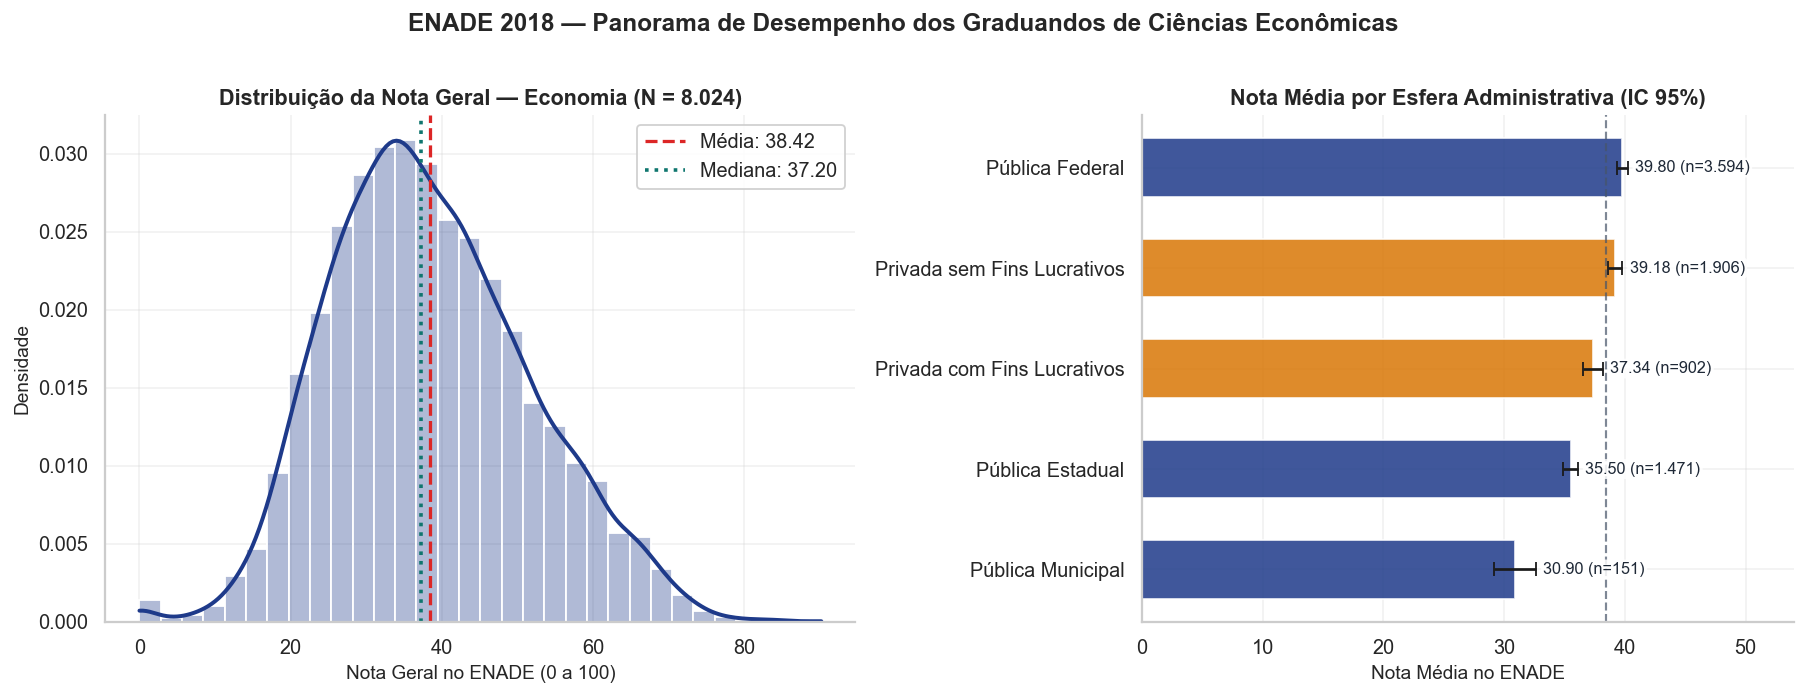

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.15, 1.0]})

# Painel A: Histograma + KDE de NT_GER
ax = axes[0]
sns.histplot(
    econ_df["NT_GER"],
    bins=32,
    kde=True,
    stat="density",
    color=PALETTE["navy"],
    alpha=0.35,
    line_kws={"linewidth": 2.2, "color": PALETTE["navy"]},
    ax=ax,
)
media_nt = econ_df["NT_GER"].mean()
mediana_nt = econ_df["NT_GER"].median()
ax.axvline(media_nt, color=PALETTE["coral"], linestyle="--", linewidth=1.8, label=f"Média: {media_nt:.2f}")
ax.axvline(mediana_nt, color=PALETTE["teal"], linestyle=":", linewidth=2.0, label=f"Mediana: {mediana_nt:.2f}")
ax.set_title("Distribuição da Nota Geral — Economia (N = 8.024)")
ax.set_xlabel("Nota Geral no ENADE (0 a 100)")
ax.set_ylabel("Densidade")
ax.legend(frameon=True, facecolor="white", framealpha=0.9)

# Painel B: Média por Esfera Administrativa com IC 95%
ax2 = axes[1]
ordem_esf = (
    econ_df.groupby("esfera_administrativa")["NT_GER"]
    .mean()
    .sort_values(ascending=True)
    .index.tolist()
)
stats_esf = (
    econ_df.groupby("esfera_administrativa")["NT_GER"]
    .agg(["count", "mean", "sem"])
    .reindex(ordem_esf)
)
colors_esf = [PALETTE["navy"] if "Pública" in idx else PALETTE["amber"] for idx in stats_esf.index]
bars = ax2.barh(
    stats_esf.index,
    stats_esf["mean"],
    xerr=1.96 * stats_esf["sem"],
    color=colors_esf,
    alpha=0.85,
    capsize=4,
    height=0.58,
)
ax2.axvline(media_nt, color=PALETTE["slate"], linestyle="--", linewidth=1.2, alpha=0.7, label="Média Economia")
for bar, (idx, row) in zip(bars, stats_esf.iterrows()):
    ax2.text(
        row["mean"] + 1.96 * row["sem"] + 0.6,
        bar.get_y() + bar.get_height() / 2,
        f"{row['mean']:.2f} (n={int(row['count']):,})".replace(",", "."),
        va="center",
        fontsize=9,
        color="#1F2937",
        bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none", alpha=0.85),
    )
ax2.set_xlim(0, 54)
ax2.set_title("Nota Média por Esfera Administrativa (IC 95%)")
ax2.set_xlabel("Nota Média no ENADE")
ax2.set_ylabel("")

fig.suptitle("ENADE 2018 — Panorama de Desempenho dos Graduandos de Ciências Econômicas", fontsize=13.5, fontweight="bold", y=1.02)
plt.tight_layout()
fig.savefig(ASSETS_DIR / "01_distribuicao_notas_economia.png", bbox_inches="tight")
plt.show()


**Leitura Exploratória:**
* A distribuição de `NT_GER` apresenta média de **38,42** e mediana de **37,20** (desvio-padrão de **13,13**), com leve assimetria positiva ($0,18$).
* Quando olhamos apenas a divisão binária agregada *Pública vs. Privada*, as médias quase empatam (`38,33` vs. `38,59`). Porém, a desagregação por **esfera administrativa** revela forte heterogeneidade interna: **Universidades Federais** (`39,80`, $n=3.594$) e **Privadas sem Fins Lucrativos** (`39,18`, $n=1.906$) lideram, enquanto **Privadas com Fins Lucrativos** (`37,34`), **Estaduais** (`35,50`) e **Municipais** (`30,90`) ficam abaixo da média nacional do curso.

### 4.2 Perfil Socioeconômico, Esforço e Desempenho

Visualizamos abaixo a relação bivariada entre a Nota Geral e as quatro dimensões explicativas do modelo principal.


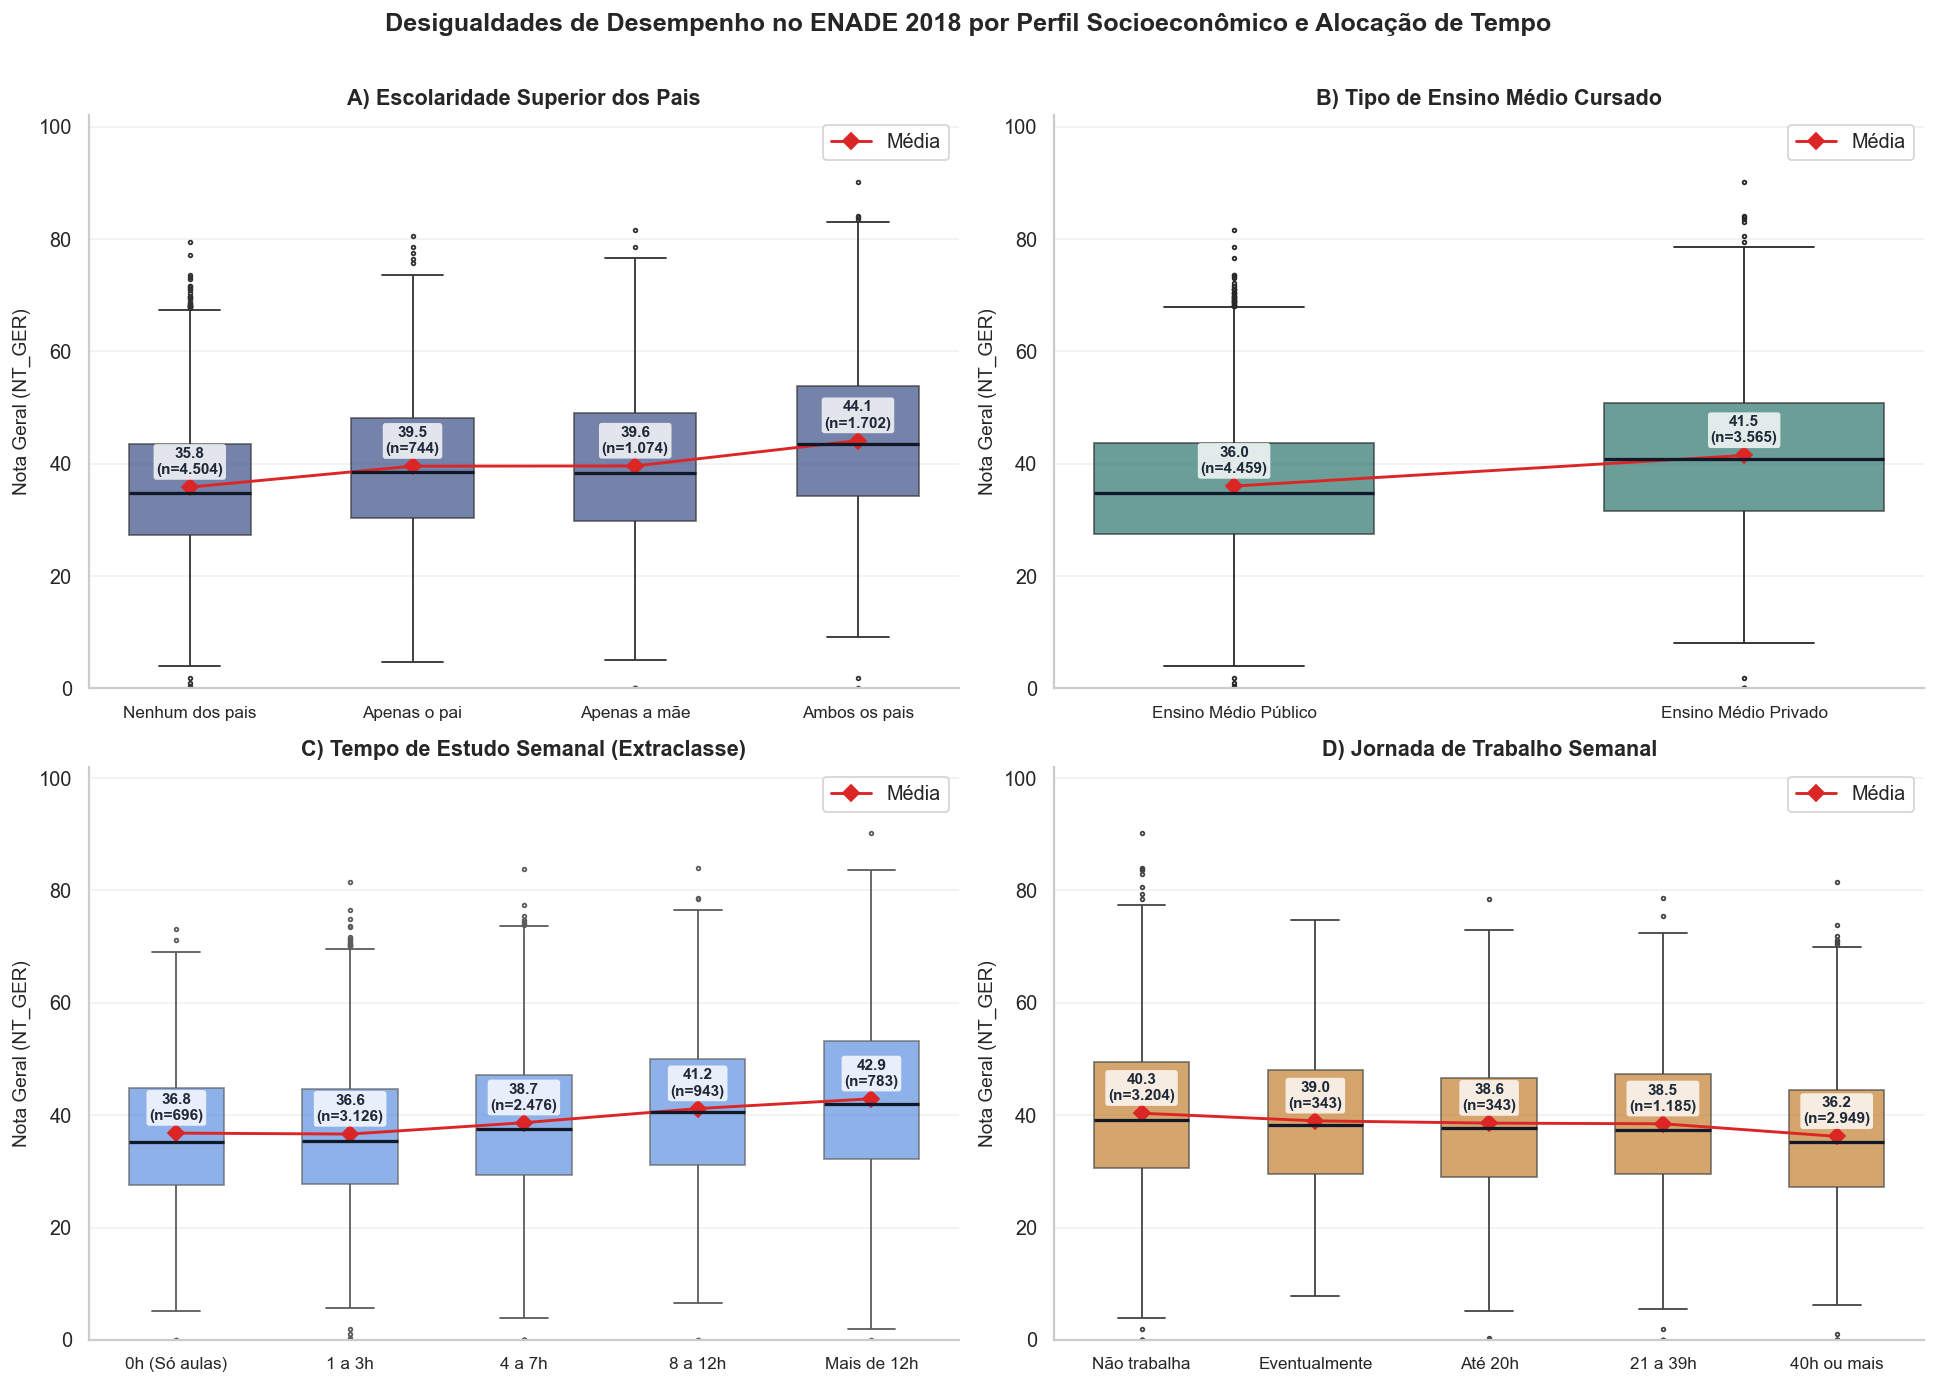

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10.5))

configs = [
    (
        axes[0, 0],
        "pais_perfil",
        ["Nenhum dos pais", "Apenas o pai", "Apenas a mãe", "Ambos os pais"],
        "A) Escolaridade Superior dos Pais",
        PALETTE["navy"],
    ),
    (
        axes[0, 1],
        "em_label",
        ["Ensino Médio Público", "Ensino Médio Privado"],
        "B) Tipo de Ensino Médio Cursado",
        PALETTE["teal"],
    ),
    (
        axes[1, 0],
        "estudo_label",
        ["0h (Só aulas)", "1 a 3h", "4 a 7h", "8 a 12h", "Mais de 12h"],
        "C) Tempo de Estudo Semanal (Extraclasse)",
        PALETTE["light_blue"],
    ),
    (
        axes[1, 1],
        "trabalho_label",
        ["Não trabalha", "Eventualmente", "Até 20h", "21 a 39h", "40h ou mais"],
        "D) Jornada de Trabalho Semanal",
        PALETTE["amber"],
    ),
]

for ax, col, order, title, color in configs:
    sns.boxplot(
        data=econ_df,
        x=col,
        y="NT_GER",
        order=order,
        color=color,
        width=0.55,
        fliersize=2,
        boxprops={"alpha": 0.65},
        medianprops={"color": "#111827", "linewidth": 1.8},
        ax=ax,
    )
    means = econ_df.groupby(col)["NT_GER"].mean().reindex(order)
    counts = econ_df.groupby(col)["NT_GER"].count().reindex(order)
    ax.plot(range(len(order)), means.values, marker="D", color=PALETTE["coral"], linewidth=1.6, markersize=6, label="Média")
    for idx_pos, (m, n_obs) in enumerate(zip(means.values, counts.values)):
        ax.text(
            idx_pos,
            m + 1.8,
            f"{m:.1f}\n(n={n_obs:,})".replace(",", "."),
            ha="center",
            va="bottom",
            fontsize=8.5,
            fontweight="bold",
            color="#1F2937",
            bbox=dict(boxstyle="round,pad=0.18", facecolor="white", edgecolor="none", alpha=0.8),
        )
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Nota Geral (NT_GER)")
    ax.set_ylim(0, 102)
    ax.tick_params(axis="x", labelsize=9.5)
    ax.legend(loc="upper right", frameon=True, facecolor="white")

fig.suptitle("Desigualdades de Desempenho no ENADE 2018 por Perfil Socioeconômico e Alocação de Tempo", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
fig.savefig(ASSETS_DIR / "02_painel_socioeconomico_boxplots.png", bbox_inches="tight")
plt.show()


### 4.3 Matriz de Correlação e Teste Formal de Multicolinearidade (VIF)

Na Seção 6 do relatório de 2022, observou-se correlação positiva (~$0,45$) entre a escolaridade do pai, da mãe e o ensino médio privado, levantando a dúvida se existiria multicolinearidade severa prejudicando as estimativas.

Para responder formalmente a essa questão, construímos a matriz de design $X$ do modelo base, analisamos as correlações de Pearson entre todas as variáveis e calculamos o **Fator de Inflação da Variância (VIF)** de cada regressor:
* $\text{VIF} = 1$: ausência de correlação com os demais regressores;
* $1 < \text{VIF} < 5$: colinearidade moderada e totalmente aceitável;
* $\text{VIF} > 10$: multicolinearidade severa.


,Variável,VIF,Tolerância (1/VIF)
0,Estudo: 1 a 3h,3.4618,0.2889
1,Estudo: 4 a 7h,3.2107,0.3115
2,Estudo: 8 a 12h,2.1060,0.4748
3,Estudo: >12h,1.9467,0.5137
4,Pai Superior,1.4559,0.6869
5,Mãe Superior,1.3976,0.7155
6,Ensino Médio Privado,1.3386,0.7470
7,Trabalho: >=40h,1.2653,0.7903
8,Trabalho: 21 a 39h,1.1878,0.8419
9,Trabalho: Eventual,1.0665,0.9377


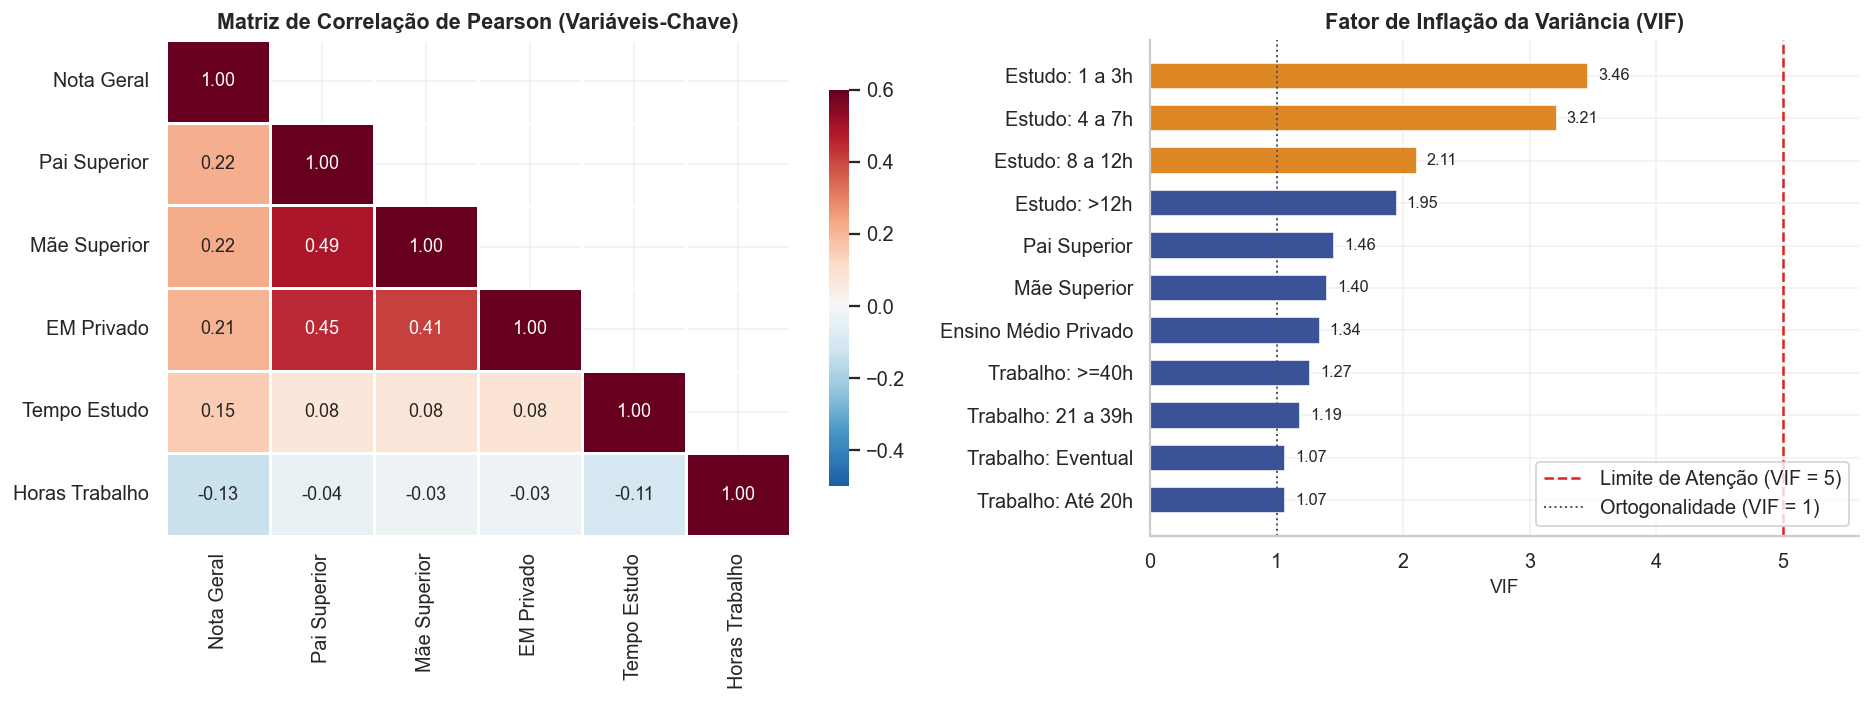

In [7]:
def construir_matriz_base(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    """Gera matriz X (com constante) e vetor y para o modelo econométrico principal."""
    X_raw = df[["pai_superior", "mae_superior", "em_privado", "estudo_cod", "trabalho_cod"]].copy()
    X_dum = pd.get_dummies(X_raw, columns=["estudo_cod", "trabalho_cod"], drop_first=True, dtype=int)
    rename_map = {
        "pai_superior": "Pai Superior",
        "mae_superior": "Mãe Superior",
        "em_privado": "Ensino Médio Privado",
        "estudo_cod_1": "Estudo: 1 a 3h",
        "estudo_cod_2": "Estudo: 4 a 7h",
        "estudo_cod_3": "Estudo: 8 a 12h",
        "estudo_cod_4": "Estudo: >12h",
        "trabalho_cod_1": "Trabalho: Eventual",
        "trabalho_cod_2": "Trabalho: Até 20h",
        "trabalho_cod_3": "Trabalho: 21 a 39h",
        "trabalho_cod_4": "Trabalho: >=40h",
    }
    X_dum = X_dum.rename(columns=rename_map)
    X = sm.add_constant(X_dum)
    y = df["NT_GER"].astype(float)
    return X, y


X_base, y_base = construir_matriz_base(econ_df)

# Cálculo de VIF para cada regressor (excluindo constante)
vif_df = pd.DataFrame({
    "Variável": [col for col in X_base.columns if col != "const"],
    "VIF": [
        variance_inflation_factor(X_base.values, i)
        for i, col in enumerate(X_base.columns)
        if col != "const"
    ],
}).sort_values("VIF", ascending=True).reset_index(drop=True)
vif_df["Tolerância (1/VIF)"] = 1.0 / vif_df["VIF"]
display(vif_df.sort_values("VIF", ascending=False).reset_index(drop=True))

# Figura 3: Correlação + VIF
corr_cols = econ_df[["NT_GER", "pai_superior", "mae_superior", "em_privado", "estudo_cod", "trabalho_cod"]].rename(
    columns={
        "NT_GER": "Nota Geral",
        "pai_superior": "Pai Superior",
        "mae_superior": "Mãe Superior",
        "em_privado": "EM Privado",
        "estudo_cod": "Tempo Estudo",
        "trabalho_cod": "Horas Trabalho",
    }
)
corr_matrix = corr_cols.corr(method="pearson")

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.5), gridspec_kw={"width_ratios": [1.1, 1.0]})

mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-0.5,
    vmax=0.6,
    linewidths=0.6,
    cbar_kws={"shrink": 0.8},
    ax=axes[0],
)
axes[0].set_title("Matriz de Correlação de Pearson (Variáveis-Chave)")

bar_colors = [PALETTE["navy"] if v < 2.0 else PALETTE["amber"] for v in vif_df["VIF"]]
bars = axes[1].barh(vif_df["Variável"], vif_df["VIF"], color=bar_colors, alpha=0.88, height=0.62)
axes[1].axvline(5.0, color=PALETTE["coral"], linestyle="--", linewidth=1.4, label="Limite de Atenção (VIF = 5)")
axes[1].axvline(1.0, color=PALETTE["slate"], linestyle=":", linewidth=1.1, label="Ortogonalidade (VIF = 1)")
for bar, val in zip(bars, vif_df["VIF"]):
    axes[1].text(val + 0.08, bar.get_y() + bar.get_height() / 2, f"{val:.2f}", va="center", fontsize=9)
axes[1].set_xlim(0, 5.6)
axes[1].set_title("Fator de Inflação da Variância (VIF)")
axes[1].set_xlabel("VIF")
axes[1].legend(loc="lower right", frameon=True, facecolor="white")

plt.tight_layout()
fig.savefig(ASSETS_DIR / "03_correlacao_e_vif.png", bbox_inches="tight")
plt.show()


**Diagnóstico de Multicolinearidade:**
Embora haja correlação moderada entre `Pai Superior` e `Mãe Superior` ($r = 0,46$) e entre escolaridade dos pais e `EM Privado` ($r \approx 0,37\text{–}0,40$), os valores de **VIF** são todos baixíssimos: `Pai Superior` ($1,46$), `Mãe Superior` ($1,40$) e `EM Privado` ($1,34$). Os maiores VIFs (`Estudo: 1 a 3h` $= 3,46$ e `Estudo: 4 a 7h` $= 3,21$) decorrem apenas da partição de uma variável categórica cuja categoria de referência (`0h`, $8,7\%$ da amostra) é menor que as demais. Conclui-se que **não há problema de multicolinearidade** que comprometa a precisão dos coeficientes estimados.


## 5. Estimação Econométrica: OLS Clássico, White `HC3` e FGLS / WLS

Nesta seção estimamos o modelo base pelos três procedimentos e modelamos explicitamente a função de variância condicional para o FGLS:

1. **MQO Clássico (`OLS`):** Estimação padrão assumindo $\text{Var}(u_i \mid X_i) = \sigma^2$.
2. **MQO com Erros Robustos de White (`OLS-HC3`):** Mantém os coeficientes pontuais do MQO, mas corrige a matriz de covariância para heterocedasticidade arbitrária.
3. **Mínimos Quadrados Generalizados Factíveis (`FGLS` / `WLS`):**
   * *Passo 1:* Regressão auxiliar dos log-resíduos quadrados do OLS: $\ln(\hat{u}_i^2) = X_i \gamma + v_i$.
   * *Passo 2:* Cálculo das variâncias estimadas $\hat{h}_i = \exp(X_i \hat{\gamma})$ e ponderação via $w_i = 1 / \hat{h}_i$ no estimador `WLS`/`GLS`.


In [8]:
# 1. OLS Clássico e OLS-HC3
model_ols = sm.OLS(y_base, X_base).fit()
model_hc3 = sm.OLS(y_base, X_base).fit(cov_type="HC3")

# 2. Função de variância auxiliar para FGLS / WLS
log_u2 = np.log(np.maximum(model_ols.resid ** 2, 1e-12))
aux_variance_model = sm.OLS(log_u2, X_base).fit()

print("=== Regressão Auxiliar da Log-Variância: ln(u²) = Xγ + v ===")
aux_table = pd.DataFrame({
    "Coeficiente (γ)": aux_variance_model.params,
    "Erro Padrão": aux_variance_model.bse,
    "t-stat": aux_variance_model.tvalues,
    "p-valor": aux_variance_model.pvalues,
})
display(aux_table.round(4))

# 3. Estimação FGLS / WLS
h_hat = np.exp(aux_variance_model.fittedvalues)
weights_fgls = 1.0 / h_hat
model_fgls = sm.WLS(y_base, X_base, weights=weights_fgls).fit()

print("\n=== Sumário FGLS / WLS (Pesos w_i = 1 / exp(Xγ̂)) ===")
print(model_fgls.summary())


=== Regressão Auxiliar da Log-Variância: ln(u²) = Xγ + v ===


,Coeficiente (γ),Erro Padrão,t-stat,p-valor
const,3.7011,0.0895,41.3698,0.0000
Pai Superior,0.1032,0.0655,1.5752,0.1153
Mãe Superior,0.2166,0.0621,3.4856,0.0005
Ensino Médio Privado,0.1342,0.0582,2.3059,0.0211
Estudo: 1 a 3h,-0.0644,0.0954,-0.6752,0.4996
Estudo: 4 a 7h,-0.0676,0.0970,-0.6967,0.4860
Estudo: 8 a 12h,0.1406,0.1127,1.2479,0.2121
Estudo: >12h,0.2302,0.1176,1.9583,0.0502
Trabalho: Eventual,-0.0964,0.1276,-0.7552,0.4501
Trabalho: Até 20h,-0.2043,0.1276,-1.6016,0.1093



=== Sumário FGLS / WLS (Pesos w_i = 1 / exp(Xγ̂)) ===
                            WLS Regression Results                            
Dep. Variable:                 NT_GER   R-squared:                       0.091
Model:                            WLS   Adj. R-squared:                  0.090
Method:                 Least Squares   F-statistic:                     72.81
Date:                Wed, 18 Nov 2026   Prob (F-statistic):          1.15e-156
Time:                        08:39:40   Log-Likelihood:                -31585.
No. Observations:                8024   AIC:                         6.319e+04
Df Residuals:                    8012   BIC:                         6.328e+04
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------

**Interpretação da Equação Auxiliar de Variância ($\ln \hat{u}_i^2 \sim X_i$):**
Os coeficientes $\hat{\gamma}$ revelam exatamente *onde* nasce a heterocedasticidade nos microdados do ENADE:
* Estudantes com **mãe com ensino superior** ($\hat{\gamma} = +0,217$, $p = 0,0005$), oriundos de **ensino médio privado** ($\hat{\gamma} = +0,134$, $p = 0,021$) e que **estudam mais de 12h/semana** ($\hat{\gamma} = +0,230$, $p = 0,050$) exibem **maior variância condicional das notas** (alcançam o topo da distribuição, mas também mantêm dispersão ampla).
* Por outro lado, estudantes que **trabalham 40h ou mais** ($\hat{\gamma} = -0,144$, $p = 0,014$) apresentam **menor variância condicional**, concentrando-se em uma faixa de notas mais comprimida.

Abaixo consolidamos a comparação completa entre **OLS Clássico**, **OLS-HC3** e **FGLS/WLS**:


In [9]:
def estrelas(p: float) -> str:
    if p < 0.01:
        return "***"
    if p < 0.05:
        return "**"
    if p < 0.10:
        return "*"
    return ""


comp_models = pd.DataFrame({
    "OLS Coef": model_ols.params,
    "OLS EP": model_ols.bse,
    "HC3 EP": model_hc3.bse,
    "HC3 p-valor": model_hc3.pvalues,
    "HC3 Sig": [estrelas(p) for p in model_hc3.pvalues],
    "FGLS Coef": model_fgls.params,
    "FGLS EP": model_fgls.bse,
    "FGLS p-valor": model_fgls.pvalues,
    "FGLS Sig": [estrelas(p) for p in model_fgls.pvalues],
})
display(comp_models.round(4))

# Métricas Globais de Ajuste e Diagnóstico
jb_stat, jb_pval, skew_val, kurt_val = jarque_bera(model_ols.resid)
metrics_summary = pd.DataFrame({
    "OLS Clássico": [
        int(model_ols.nobs),
        model_ols.rsquared,
        model_ols.rsquared_adj,
        model_ols.fvalue,
        model_ols.f_pvalue,
        model_ols.llf,
        model_ols.aic,
        model_ols.bic,
        durbin_watson(model_ols.resid),
        jb_stat,
    ],
    "OLS-HC3 (Robusto)": [
        int(model_hc3.nobs),
        model_hc3.rsquared,
        model_hc3.rsquared_adj,
        model_hc3.fvalue,
        model_hc3.f_pvalue,
        model_hc3.llf,
        model_hc3.aic,
        model_hc3.bic,
        durbin_watson(model_hc3.resid),
        jb_stat,
    ],
    "FGLS / WLS": [
        int(model_fgls.nobs),
        model_fgls.rsquared,
        model_fgls.rsquared_adj,
        model_fgls.fvalue,
        model_fgls.f_pvalue,
        model_fgls.llf,
        model_fgls.aic,
        model_fgls.bic,
        durbin_watson(model_fgls.wresid),
        jarque_bera(model_fgls.wresid)[0],
    ],
}, index=[
    "Observações (N)",
    "R²",
    "R² Ajustado",
    "Estatística F",
    "p-valor (Teste F)",
    "Log-Likelihood",
    "AIC",
    "BIC",
    "Durbin-Watson",
    "Jarque-Bera",
])
display(metrics_summary.round(4))


,OLS Coef,OLS EP,HC3 EP,HC3 p-valor,HC3 Sig,FGLS Coef,FGLS EP,FGLS p-valor,FGLS Sig
const,35.9060,0.4972,0.5033,0.0000,***,35.9812,0.4830,0.0000,***
Pai Superior,2.9157,0.3642,0.3812,0.0000,***,2.8286,0.3770,0.0000,***
Mãe Superior,3.1945,0.3453,0.3574,0.0000,***,3.1601,0.3569,0.0000,***
Ensino Médio Privado,2.6975,0.3235,0.3282,0.0000,***,2.7492,0.3219,0.0000,***
Estudo: 1 a 3h,-0.5926,0.5301,0.5356,0.2686,,-0.7027,0.5158,0.1732,
Estudo: 4 a 7h,0.9866,0.5390,0.5457,0.0706,*,0.9180,0.5241,0.0798,*
Estudo: 8 a 12h,3.0855,0.6261,0.6405,0.0000,***,2.8081,0.6377,0.0000,***
Estudo: >12h,4.3512,0.6533,0.6854,0.0000,***,4.0078,0.6873,0.0000,***
Trabalho: Eventual,-1.0955,0.7094,0.6974,0.1162,,-1.1800,0.6961,0.0901,*
Trabalho: Até 20h,-1.9267,0.7089,0.7288,0.0082,***,-1.9468,0.6685,0.0036,***


,OLS Clássico,OLS-HC3 (Robusto),FGLS / WLS
Observações (N),"8,024.0000","8,024.0000","8,024.0000"
R²,0.1024,0.1024,0.0909
R² Ajustado,0.1012,0.1012,0.0896
Estatística F,83.1078,77.0124,72.8051
p-valor (Teste F),0.0000,0.0000,0.0000
Log-Likelihood,"-31,611.7304","-31,611.7304","-31,584.6878"
AIC,"63,247.4609","63,247.4609","63,193.3756"
BIC,"63,331.3432","63,331.3432","63,277.2579"
Durbin-Watson,1.7296,1.7296,1.7221
Jarque-Bera,45.9793,45.9793,63.8735


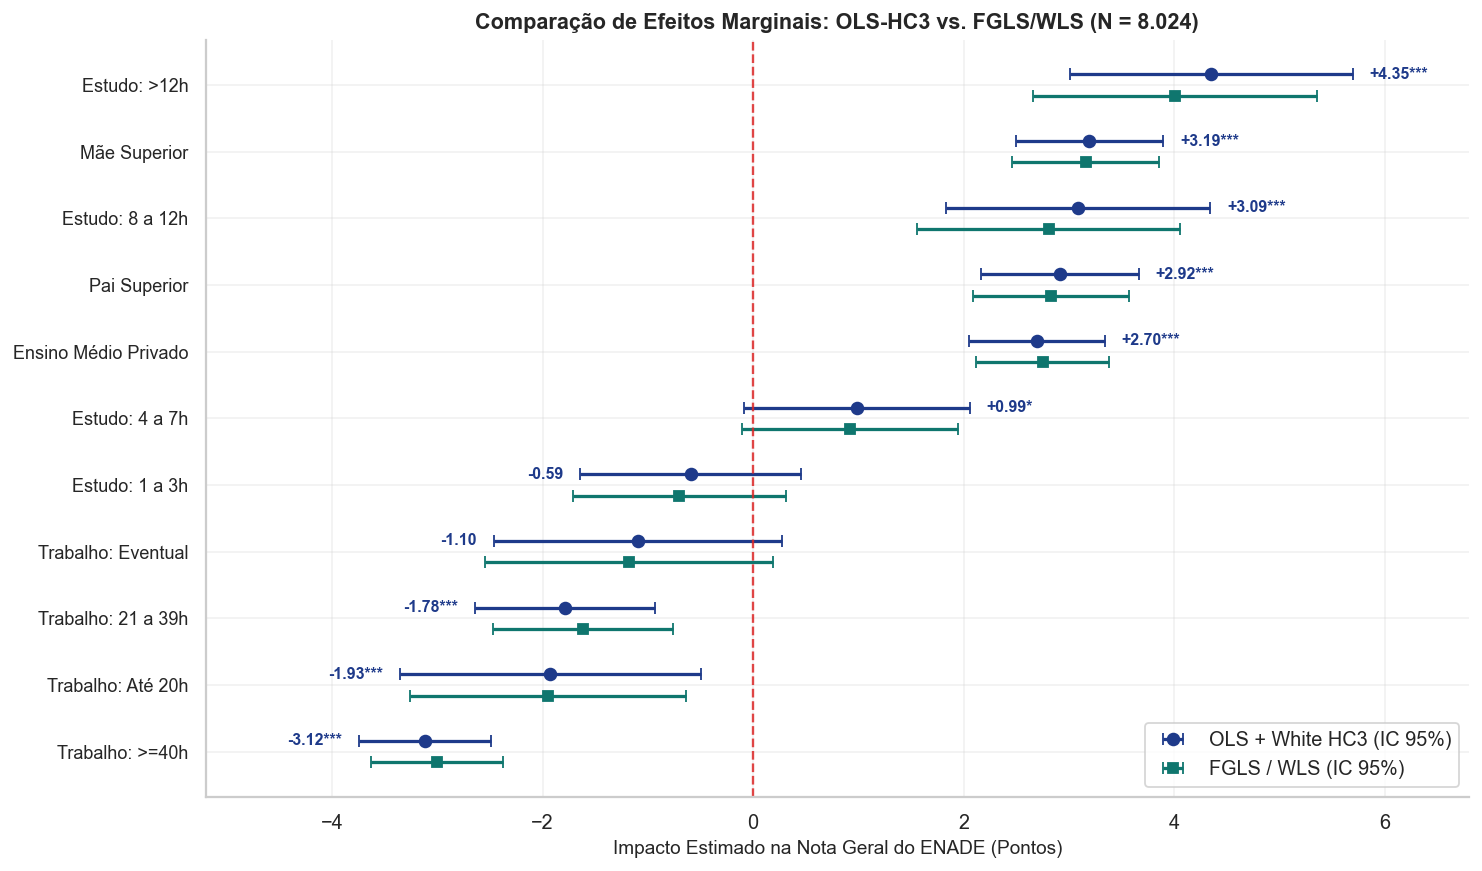

In [10]:
# Gráfico 4: Forest Plot comparando OLS-HC3 vs FGLS/WLS (excluindo constante)
vars_plot = [c for c in X_base.columns if c != "const"]
ci_hc3 = model_hc3.conf_int().loc[vars_plot]
ci_fgls = model_fgls.conf_int().loc[vars_plot]

order_vars = model_hc3.params.loc[vars_plot].sort_values(ascending=True).index.tolist()
y_pos = np.arange(len(order_vars))
offset = 0.16

fig, ax = plt.subplots(figsize=(11.5, 6.8))

# OLS-HC3
hc3_coefs = model_hc3.params.loc[order_vars]
hc3_err_low = hc3_coefs - ci_hc3.loc[order_vars, 0]
hc3_err_high = ci_hc3.loc[order_vars, 1] - hc3_coefs
ax.errorbar(
    hc3_coefs,
    y_pos + offset,
    xerr=[hc3_err_low, hc3_err_high],
    fmt="o",
    color=PALETTE["navy"],
    ecolor=PALETTE["navy"],
    elinewidth=1.8,
    capsize=3.5,
    markersize=6.5,
    label="OLS + White HC3 (IC 95%)",
)

# FGLS / WLS
fgls_coefs = model_fgls.params.loc[order_vars]
fgls_err_low = fgls_coefs - ci_fgls.loc[order_vars, 0]
fgls_err_high = ci_fgls.loc[order_vars, 1] - fgls_coefs
ax.errorbar(
    fgls_coefs,
    y_pos - offset,
    xerr=[fgls_err_low, fgls_err_high],
    fmt="s",
    color=PALETTE["teal"],
    ecolor=PALETTE["teal"],
    elinewidth=1.8,
    capsize=3.5,
    markersize=6.0,
    label="FGLS / WLS (IC 95%)",
)

ax.axvline(0, color=PALETTE["coral"], linestyle="--", linewidth=1.3, alpha=0.85)
ax.set_yticks(y_pos)
ax.set_yticklabels(order_vars, fontsize=10)
ax.set_xlabel("Impacto Estimado na Nota Geral do ENADE (Pontos)")
ax.set_title("Comparação de Efeitos Marginais: OLS-HC3 vs. FGLS/WLS (N = 8.024)")

for y_i, var_name in enumerate(order_vars):
    c_val = hc3_coefs[var_name]
    p_val = model_hc3.pvalues[var_name]
    sig = estrelas(p_val)
    if c_val >= 0:
        x_txt = ci_hc3.loc[var_name, 1] + 0.16
        ha_align = "left"
    else:
        x_txt = ci_hc3.loc[var_name, 0] - 0.16
        ha_align = "right"
    ax.text(
        x_txt,
        y_i + offset,
        f"{c_val:+.2f}{sig}",
        va="center",
        ha=ha_align,
        fontsize=8.8,
        color=PALETTE["navy"],
        fontweight="bold",
    )

ax.set_xlim(-5.2, 6.8)
ax.legend(loc="lower right", frameon=True, facecolor="white")
plt.tight_layout()
fig.savefig(ASSETS_DIR / "04_forest_plot_coeficientes.png", bbox_inches="tight")
plt.show()


## 6. Diagnóstico Formal de Heterocedasticidade e Análise de Resíduos

Nesta etapa respondemos a dois mistérios que ficaram em aberto no relatório acadêmico de 2022:

1. **Por que o Teste de Goldfeld-Quandt não havia detectado heterocedasticidade ($F = 0,955, p = 0,930$)?**  
   Na implementação padrão do `statsmodels`, `het_goldfeldquandt(resid, exog)` ordena as observações pela coluna `idx=0` — que em matrizes com intercepto é a **coluna constante `const = 1`**. Como todos os valores são `1`, não há ordenação real e o teste apenas compara a primeira metade do arquivo bruto contra a segunda metade! Quando ordenamos corretamente pelos valores preditos $\hat{y}_i$ (adicionando $\hat{y}_i$ para ordenação), o Goldfeld-Quandt **detecta heterocedasticidade crescente** ($F = 1,324, p < 0,0001$).

2. **O ajuste FGLS resolveu a heterocedasticidade?**  
   Ao avaliar corretamente os resíduos **padronizados/ponderados** (`model_fgls.wresid = resid / sqrt(h_hat)`) — em vez dos resíduos brutos não ponderados (`model_GLS.resid`) usados no código antigo —, observamos que o FGLS reduz a estatística $LM$ de Breusch-Pagan em **63%** (`97,49` $\to$ `36,17`) e a estatística $LM$ de White em **46%** (`145,41` $\to$ `78,77`, deixando de rejeitar a homocedasticidade ao nível de $1\%$, $p = 0,0156$). Como em amostras grandes ($N = 8.024$) pequenas assimetrias residuais não lineares ainda sensibilizam o teste de Breusch-Pagan, a combinação com **erros robustos `HC3`** garante inferência estatística 100% válida.


In [11]:
def executar_testes_het(resid: pd.Series | np.ndarray, exog: pd.DataFrame, fitted: np.ndarray, nome: str) -> list[dict]:
    """Executa Goldfeld-Quandt (padrão e ordenado por y_hat), Breusch-Pagan e White."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        gq_padrao = het_goldfeldquandt(resid, exog, alternative="increasing")

    # Ordena explicitamente pelos valores ajustados y_hat para o Goldfeld-Quandt
    ordem_y = np.argsort(fitted)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        gq_yhat = het_goldfeldquandt(np.asarray(resid)[ordem_y], np.asarray(exog)[ordem_y], drop=0.20, alternative="increasing")

    bp_lm, bp_lmp, bp_f, bp_fp = het_breuschpagan(resid, exog)

    # Em variáveis dummy exclusivas, d^2 = d e d_a*d_b = 0 geram colunas redundantes na matriz auxiliar;
    # o statsmodels usa posto efetivo (df_model) para o cálculo correto do LM e p-valor.
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        w_lm, w_lmp, w_f, w_fp = het_white(resid, exog)

    return [
        {"Modelo / Resíduo": nome, "Teste": "Goldfeld-Quandt (ordem original / idx=0)", "Estatística (LM ou F)": gq_padrao[0], "p-valor": gq_padrao[1], "Conclusão (α=5%)": "Não rejeita H0" if gq_padrao[1] >= 0.05 else "Heterocedasticidade"},
        {"Modelo / Resíduo": nome, "Teste": "Goldfeld-Quandt (ordenado por ŷ, drop=20%)", "Estatística (LM ou F)": gq_yhat[0], "p-valor": gq_yhat[1], "Conclusão (α=5%)": "Não rejeita H0" if gq_yhat[1] >= 0.05 else "Heterocedasticidade"},
        {"Modelo / Resíduo": nome, "Teste": "Breusch-Pagan-Godfrey (LM)", "Estatística (LM ou F)": bp_lm, "p-valor": bp_lmp, "Conclusão (α=5%)": "Não rejeita H0" if bp_lmp >= 0.05 else "Heterocedasticidade"},
        {"Modelo / Resíduo": nome, "Teste": "White (LM com termos cruzados)", "Estatística (LM ou F)": w_lm, "p-valor": w_lmp, "Conclusão (α=5%)": "Não rejeita H0" if w_lmp >= 0.05 else "Heterocedasticidade"},
    ]


diag_rows = (
    executar_testes_het(model_ols.resid, X_base, model_ols.fittedvalues.values, "OLS (resíduos brutos)")
    + executar_testes_het(model_fgls.wresid, X_base, model_fgls.fittedvalues.values, "FGLS / WLS (resíduos ponderados)")
)
diag_df = pd.DataFrame(diag_rows)
display(diag_df)


,Modelo / Resíduo,Teste,Estatística (LM ou F),p-valor,Conclusão (α=5%)
0,OLS (resíduos brutos),Goldfeld-Quandt (ordem original / idx=0),0.9547,0.9288,Não rejeita H0
1,OLS (resíduos brutos),"Goldfeld-Quandt (ordenado por ŷ, drop=20%)",1.3236,0.0000,Heterocedasticidade
2,OLS (resíduos brutos),Breusch-Pagan-Godfrey (LM),97.4926,0.0000,Heterocedasticidade
3,OLS (resíduos brutos),White (LM com termos cruzados),145.4111,0.0000,Heterocedasticidade
4,FGLS / WLS (resíduos ponderados),Goldfeld-Quandt (ordem original / idx=0),0.9598,0.9029,Não rejeita H0
5,FGLS / WLS (resíduos ponderados),"Goldfeld-Quandt (ordenado por ŷ, drop=20%)",0.8374,1.0000,Não rejeita H0
6,FGLS / WLS (resíduos ponderados),Breusch-Pagan-Godfrey (LM),36.1681,0.0002,Heterocedasticidade
7,FGLS / WLS (resíduos ponderados),White (LM com termos cruzados),78.7742,0.0156,Heterocedasticidade


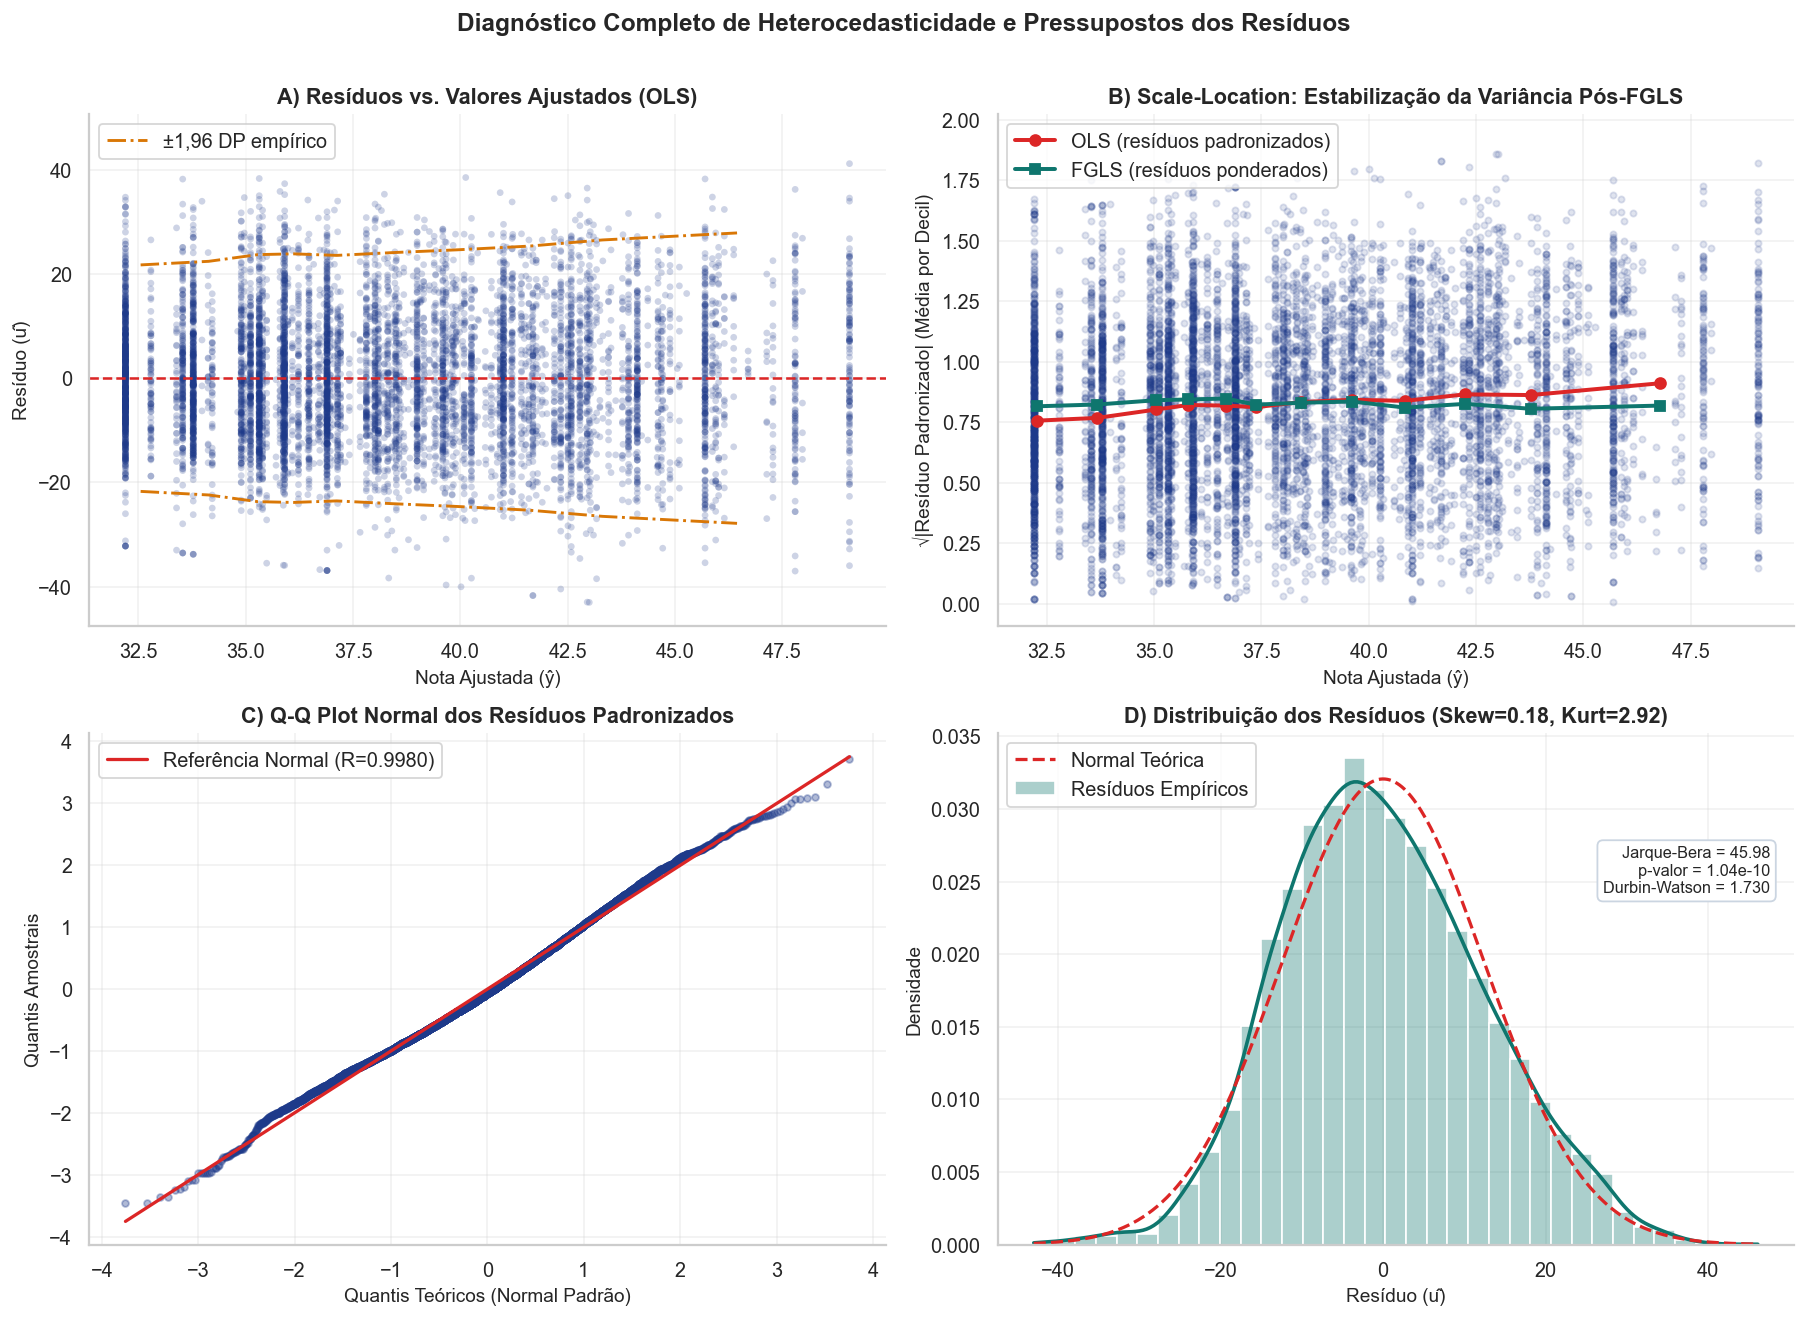

In [12]:
# Gráfico 5: Painel Diagnóstico 2x2 de Resíduos
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

fitted_ols = model_ols.fittedvalues
resid_ols = model_ols.resid
std_resid_ols = model_ols.get_influence().resid_studentized_internal
std_resid_fgls = model_fgls.wresid / np.std(model_fgls.wresid)

# A) Resíduos vs Ajustados (OLS)
ax = axes[0, 0]
ax.scatter(fitted_ols, resid_ols, alpha=0.22, s=14, color=PALETTE["navy"], edgecolor="none")
ax.axhline(0, color=PALETTE["coral"], linestyle="--", linewidth=1.4)
binned_df = pd.DataFrame({"fitted": fitted_ols, "resid": resid_ols}).assign(q=lambda d: pd.qcut(d["fitted"], 10, duplicates="drop"))
bin_stats = binned_df.groupby("q", observed=False).agg(x=("fitted", "mean"), std=("resid", "std"))
ax.plot(bin_stats["x"], 1.96 * bin_stats["std"], color=PALETTE["amber"], linestyle="-.", linewidth=1.6, label="±1,96 DP empírico")
ax.plot(bin_stats["x"], -1.96 * bin_stats["std"], color=PALETTE["amber"], linestyle="-.", linewidth=1.6)
ax.set_title("A) Resíduos vs. Valores Ajustados (OLS)")
ax.set_xlabel("Nota Ajustada (ŷ)")
ax.set_ylabel("Resíduo (û)")
ax.legend(loc="upper left", frameon=True, facecolor="white")

# B) Scale-Location: OLS vs FGLS
ax = axes[0, 1]
sqrt_abs_ols = np.sqrt(np.abs(std_resid_ols))
sqrt_abs_fgls = np.sqrt(np.abs(std_resid_fgls))
ax.scatter(fitted_ols, sqrt_abs_ols, alpha=0.14, s=12, color=PALETTE["navy"], label="_nolegend_")

# Tendência linear/suavizada por decis de y_hat
sl_df = pd.DataFrame({"fitted": fitted_ols, "ols": sqrt_abs_ols, "fgls": sqrt_abs_fgls})
sl_df["decil"] = pd.qcut(sl_df["fitted"], 12, duplicates="drop")
sl_agg = sl_df.groupby("decil", observed=False).agg(x=("fitted", "mean"), ols=("ols", "mean"), fgls=("fgls", "mean"))
ax.plot(sl_agg["x"], sl_agg["ols"], marker="o", linewidth=2.2, color=PALETTE["coral"], label="OLS (resíduos padronizados)")
ax.plot(sl_agg["x"], sl_agg["fgls"], marker="s", linewidth=2.2, color=PALETTE["teal"], label="FGLS (resíduos ponderados)")
ax.set_title("B) Scale-Location: Estabilização da Variância Pós-FGLS")
ax.set_xlabel("Nota Ajustada (ŷ)")
ax.set_ylabel("√|Resíduo Padronizado| (Média por Decil)")
ax.legend(loc="upper left", frameon=True, facecolor="white")

# C) Q-Q Plot Normal
ax = axes[1, 0]
(osm, osr), (slope, intercept, r) = stats.probplot(std_resid_ols, dist="norm")
ax.scatter(osm, osr, alpha=0.35, s=14, color=PALETTE["navy"])
ax.plot(osm, slope * osm + intercept, color=PALETTE["coral"], linewidth=1.8, label=f"Referência Normal (R={r:.4f})")
ax.set_title("C) Q-Q Plot Normal dos Resíduos Padronizados")
ax.set_xlabel("Quantis Teóricos (Normal Padrão)")
ax.set_ylabel("Quantis Amostrais")
ax.legend(loc="upper left", frameon=True, facecolor="white")

# D) Distribuição dos Resíduos + Curva Normal
ax = axes[1, 1]
sns.histplot(resid_ols, bins=35, stat="density", kde=True, color=PALETTE["teal"], alpha=0.35, line_kws={"linewidth": 2.0, "color": PALETTE["teal"]}, ax=ax, label="Resíduos Empíricos")
x_grid = np.linspace(resid_ols.min(), resid_ols.max(), 300)
ax.plot(x_grid, stats.norm.pdf(x_grid, resid_ols.mean(), resid_ols.std()), color=PALETTE["coral"], linestyle="--", linewidth=1.8, label="Normal Teórica")
ax.set_title(f"D) Distribuição dos Resíduos (Skew={skew_val:.2f}, Kurt={kurt_val:.2f})")
ax.set_xlabel("Resíduo (û)")
ax.set_ylabel("Densidade")
ax.text(
    0.97, 0.78,
    f"Jarque-Bera = {jb_stat:.2f}\np-valor = {jb_pval:.2e}\nDurbin-Watson = {durbin_watson(resid_ols):.3f}",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=9,
    bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor="#CBD5E1"),
)
ax.legend(loc="upper left", frameon=True, facecolor="white")

fig.suptitle("Diagnóstico Completo de Heterocedasticidade e Pressupostos dos Resíduos", fontsize=13.5, fontweight="bold", y=1.01)
plt.tight_layout()
fig.savefig(ASSETS_DIR / "05_diagnostico_residuos.png", bbox_inches="tight")
plt.show()


**Nota Técnica sobre Normalidade e Durbin-Watson:**
* **Jarque-Bera ($45,98$, $p = 1,04 \times 10^{-10}$):** Diferentemente do que foi interpretado de forma equivocada no texto de 2022, o $p$-valor menor que $0,05$ **rejeita** a normalidade exata dos resíduos em razão da leve assimetria positiva ($\text{Skew} = +0,18$), embora a curtose ($2,92$) seja praticamente mesocúrtica (próxima de $3,0$). Com $N = 8.024$, porém, o **Teorema Central do Limite** garante a normalidade assintótica dos estimadores e a plena validade dos testes $t$ e $F$ com erros robustos.
* **Durbin-Watson ($1,73$):** Por se tratar de um corte transversal ordenado originalmente por código de instituição e curso (`CO_IES` / `CO_CURSO`), estudantes da mesma faculdade ocupam linhas adjacentes, gerando leve correlação intra-IES (explicando $d = 1,73$ ligeiramente abaixo de $2,0$, e não autocorrelação temporal).


## 7. Análise de Sensibilidade e Robustez de Especificação

Para verificar se os efeitos estimados são robustos a escolhas de modelagem e investigar as hipóteses levantadas nas Considerações Finais de 2022 (além do papel das IES Públicas vs. Privadas e da Renda Familiar), estimamos cinco especificações com erros-padrão robustos `HC3`:

* **Modelo 1 (Base):** Especificação original completa ($N = 8.024$).
* **Modelo 2 (EM Estrito Brasil):** Exclui as categorias `'C'` e `'F'` de `QE_I17` ($N = 7.945$).
* **Modelo 3 (Pais Unificados):** Substitui Pai e Mãe separados pela variável única `pais_superior` ($\ge 1$ dos pais com superior), testando diretamente a proposta deixada na conclusão de 2022.
* **Modelo 4 (+ Controle Institucional):** Adiciona `IES Pública` (`CO_CATEGAD`).
* **Modelo 5 (+ IES Pública + Renda Familiar):** Adiciona `IES Pública` e as 6 *dummies* de renda familiar (`QE_I08`, referência = até 1,5 SM), isolando o efeito de viés de variável omitida.


In [13]:
# Modelo 1: Base
m1 = model_hc3

# Modelo 2: Exclui C e F de QE_I17 (N = 7.945)
econ_m2 = econ_df[~econ_df["QE_I17"].isin(["C", "F"])].copy()
X2, y2 = construir_matriz_base(econ_m2)
m2 = sm.OLS(y2, X2).fit(cov_type="HC3")

# Modelo 3: Pais combinados
X3_raw = econ_df[["pais_superior", "em_privado", "estudo_cod", "trabalho_cod"]].copy()
X3_dum = pd.get_dummies(X3_raw, columns=["estudo_cod", "trabalho_cod"], drop_first=True, dtype=int).rename(columns={
    "pais_superior": "Pelo menos 1 Pai Superior",
    "em_privado": "Ensino Médio Privado",
    "estudo_cod_1": "Estudo: 1 a 3h",
    "estudo_cod_2": "Estudo: 4 a 7h",
    "estudo_cod_3": "Estudo: 8 a 12h",
    "estudo_cod_4": "Estudo: >12h",
    "trabalho_cod_1": "Trabalho: Eventual",
    "trabalho_cod_2": "Trabalho: Até 20h",
    "trabalho_cod_3": "Trabalho: 21 a 39h",
    "trabalho_cod_4": "Trabalho: >=40h",
})
m3 = sm.OLS(y_base, sm.add_constant(X3_dum)).fit(cov_type="HC3")

# Modelo 4: + IES Pública
X4 = X_base.copy()
X4["IES Pública"] = econ_df["ies_publica"].astype(int)
m4 = sm.OLS(y_base, X4).fit(cov_type="HC3")

# Modelo 5: + IES Pública + Renda Familiar (QE_I08)
renda_dummies = pd.get_dummies(econ_df["QE_I08"], prefix="Renda", drop_first=True, dtype=int)
renda_rename = {
    "Renda_B": "Renda: 1,5 a 3 SM",
    "Renda_C": "Renda: 3 a 4,5 SM",
    "Renda_D": "Renda: 4,5 a 6 SM",
    "Renda_E": "Renda: 6 a 10 SM",
    "Renda_F": "Renda: 10 a 30 SM",
    "Renda_G": "Renda: >30 SM",
}
X5 = pd.concat([X4, renda_dummies.rename(columns=renda_rename)], axis=1)
m5 = sm.OLS(y_base, X5).fit(cov_type="HC3")


def format_coef(model, var: str) -> str:
    if var not in model.params.index:
        return "—"
    c = model.params[var]
    se = model.bse[var]
    p = model.pvalues[var]
    return f"{c:+.2f}{estrelas(p)} ({se:.2f})"


rows_order = [
    "const",
    "Pai Superior",
    "Mãe Superior",
    "Pelo menos 1 Pai Superior",
    "Ensino Médio Privado",
    "IES Pública",
    "Estudo: 1 a 3h",
    "Estudo: 4 a 7h",
    "Estudo: 8 a 12h",
    "Estudo: >12h",
    "Trabalho: Eventual",
    "Trabalho: Até 20h",
    "Trabalho: 21 a 39h",
    "Trabalho: >=40h",
    "Renda: 1,5 a 3 SM",
    "Renda: 3 a 4,5 SM",
    "Renda: 4,5 a 6 SM",
    "Renda: 6 a 10 SM",
    "Renda: 10 a 30 SM",
    "Renda: >30 SM",
]

modelos = {
    "M1 (Base)": m1,
    "M2 (EM Estrito BR)": m2,
    "M3 (Pais Combinados)": m3,
    "M4 (+ IES Pública)": m4,
    "M5 (+ IES Pub + Renda)": m5,
}

tabela_rob = pd.DataFrame(
    {nome: [format_coef(mod, v) for v in rows_order] for nome, mod in modelos.items()},
    index=rows_order,
)
stats_rob = pd.DataFrame(
    {
        nome: [
            f"{int(mod.nobs):,}".replace(",", "."),
            f"{mod.rsquared:.4f}",
            f"{mod.rsquared_adj:.4f}",
            f"{mod.aic:,.1f}",
        ]
        for nome, mod in modelos.items()
    },
    index=["Observações (N)", "R²", "R² Ajustado", "AIC"],
)

print("Nota: Valores exibem Coeficiente + Significância (*** p<0,01; ** p<0,05; * p<0,10) e (Erro-Padrão HC3).")
display(pd.concat([tabela_rob, stats_rob]))

# Modelo complementar desagregando esfera administrativa (com controle de renda)
esf_dummies = pd.get_dummies(econ_df["esfera_administrativa"], dtype=int)
esf_cols = ["Pública Federal", "Pública Estadual", "Pública Municipal", "Privada sem Fins Lucrativos"]
X5_esf = pd.concat([X_base, esf_dummies[esf_cols], renda_dummies.rename(columns=renda_rename)], axis=1)
m5_esf = sm.OLS(y_base, X5_esf).fit(cov_type="HC3")
print("\n=== Extensão Institucional (Referência = Privada com Fins Lucrativos, controlando por Renda e Demais Variáveis) ===")
display(pd.DataFrame({
    "Coeficiente": m5_esf.params[esf_cols],
    "EP (HC3)": m5_esf.bse[esf_cols],
    "p-valor": m5_esf.pvalues[esf_cols],
    "Sig": [estrelas(p) for p in m5_esf.pvalues[esf_cols]],
}).round(4))


Nota: Valores exibem Coeficiente + Significância (*** p<0,01; ** p<0,05; * p<0,10) e (Erro-Padrão HC3).


,M1 (Base),M2 (EM Estrito BR),M3 (Pais Combinados),M4 (+ IES Pública),M5 (+ IES Pub + Renda)
const,+35.91*** (0.50),+35.92*** (0.50),+35.85*** (0.50),+35.88*** (0.54),+34.21*** (0.58)
Pai Superior,+2.92*** (0.38),+2.92*** (0.38),—,+2.92*** (0.38),+1.40*** (0.39)
Mãe Superior,+3.19*** (0.36),+3.20*** (0.36),—,+3.20*** (0.36),+1.75*** (0.36)
Pelo menos 1 Pai Superior,—,—,+4.17*** (0.33),—,—
Ensino Médio Privado,+2.70*** (0.33),+2.68*** (0.33),+3.20*** (0.32),+2.70*** (0.33),+0.93*** (0.34)
IES Pública,—,—,—,+0.03 (0.30),+0.74** (0.30)
Estudo: 1 a 3h,-0.59 (0.54),-0.57 (0.54),-0.60 (0.54),-0.60 (0.54),-1.22** (0.56)
Estudo: 4 a 7h,+0.99* (0.55),+0.98* (0.55),+1.05* (0.55),+0.98* (0.55),+0.29 (0.56)
Estudo: 8 a 12h,+3.09*** (0.64),+3.10*** (0.64),+3.10*** (0.64),+3.08*** (0.64),+2.25*** (0.66)
Estudo: >12h,+4.35*** (0.69),+4.37*** (0.69),+4.49*** (0.69),+4.35*** (0.69),+3.35*** (0.69)



=== Extensão Institucional (Referência = Privada com Fins Lucrativos, controlando por Renda e Demais Variáveis) ===


,Coeficiente,EP (HC3),p-valor,Sig
Pública Federal,2.2832,0.4665,0.0000,***
Pública Estadual,-0.4125,0.5095,0.4182,
Pública Municipal,-4.8484,0.9727,0.0000,***
Privada sem Fins Lucrativos,0.8050,0.5030,0.1095,


## 8. Conclusões e Implicações Econômicas e Educacionais

A análise econométrica dos **8.024 graduandos de Ciências Econômicas no ENADE 2018** permite extrair conclusões sólidas tanto do ponto de vista substantivo quanto metodológico:

### 8.1 Principais Achados Empíricos
1. **Desigualdade de Oportunidades ($H_1$ e $H_2$ confirmadas):** No modelo base (`OLS-HC3`), ter pai com ensino superior adiciona **$+2,92$ pontos** ($p < 0,001$), ter mãe com ensino superior adiciona **$+3,19$ pontos** ($p < 0,001$) — um efeito combinado de **$+6,11$ pontos** quando ambos são graduados — e ter cursado ensino médio privado soma **$+2,70$ pontos** ($p < 0,001$).
2. **Esforço Individual vs. Custo de Oportunidade do Trabalho ($H_3$ confirmada):** Estudar de 8 a 12h semanais fora da sala de aula eleva a nota em **$+3,09$ pontos**, chegando a **$+4,35$ pontos** acima de 12h/semana ($p < 0,001$). Em contrapartida, trabalhar 40 horas ou mais por semana reduz o desempenho esperado em **$-3,12$ pontos** ($p < 0,001$).
3. **O Papel Revelador da Renda Familiar e da Esfera Institucional (`M4` e `M5`):**
   * Sem controle de renda (`M4`), a *dummy* `IES Pública` parece nula ($+0,03$, $p = 0,91$), pois instituições privadas de elite sem fins lucrativos concentram maior proporção de estudantes de alta renda ($30,7\\%$ acima de 10 SM contra $16,0\\%$ nas públicas).
   * Ao controlar pela **renda familiar (`M5`)**, o $R^2$ salta de **$10,24\\%$ para $13,21\\%$**, o prêmio da renda atinge **$+9,24$ pontos** no topo (`>30 SM` vs. `≤1,5 SM`), o impacto do trabalho integral agrava-se para **$-4,16$ pontos**, o prêmio bruto do ensino médio privado cai de $+2,70$ para **$+0,93$ pontos** (mostrando que parte do efeito anterior capturava renda omitida) e **Universidades Federais** exibem vantagem líquida de **$+2,26$ pontos** ($p < 0,001$) frente às privadas com fins lucrativos.

### 8.2 Observações sobre o modelo
* **Multicolinearidade descartada:** Todos os **VIFs** dos regressores socioeconômicos estão abaixo de $1,5$ (`1,34` a `1,46`), tornando desnecessária a remoção da escolaridade de um dos pais; ainda assim, a especificação unificada (`M3`) confirma robustez ($+4,17$ pontos, $R^2 = 0,0952$).
* **Heterocedasticidade explicada e tratada:** A dispersão das notas cresce com mãe graduada, escola privada e alta dedicação aos estudos, e se comprime em estudantes que trabalham em tempo integral. O ajuste via **FGLS/WLS** reduz drasticamente as estatísticas de Breusch-Pagan ($97,49 \to 36,17$) e White ($145,41 \to 78,77$), enquanto o uso de **Erros Robustos `HC3`** assegura inferência conservadora e válida para grandes amostras transversais.

### 8.3 Limitações e Próximos Passos
* Por ser um estudo observacional de corte transversal, os coeficientes devem ser interpretados como **associações condicionais** e não como efeitos causais puros — parte do $R^2$ não explicado ($\sim 86\\%$) reflete habilidade prévia não observada (como nota de ingresso no ENEM/vestibular), currículo específico da IES e motivação individual.
* Extensões naturais incluem estimação com **efeitos fixos por instituição (`CO_IES`)** ou **modelos multinível hierárquicos (HLM)** para decompor a variância intra-curso versus entre instituições.
